# Stage 10 — Early logistic regression and decision tree

This notebook has no API calls. It reads only the fresh stage-09 sample, never development cases or older model outcomes. The primary early regression relates success to human rating (per 500 points) and one/multiple solver moves. The tree explores rating, solution length and legal-move count.

Completed provider responses include incorrect, illegal, malformed and length-limited answers as operational failures; infrastructure errors are separately reported. The data gate requires all 60 cases attempted, at least 58 completed responses, at least 15 successes and 15 failures, and a passed collection audit. Small-sample inference remains provisional. Curves show conditional mean confidence intervals, not prediction guarantees. The tree is descriptive and has no out-of-sample accuracy claim.

The depth-2 numeric CART tree is implemented directly with NumPy and drawn with Matplotlib because Windows Application Control blocks a scikit-learn extension in this environment. Its Gini split, minimum-leaf and constant-feature checks run before use. The earlier scikit-learn artifacts remain historical; no system security setting was changed.

## Audit data and decide whether fitting is allowed

In [1]:

from pathlib import Path
import json,hashlib,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning
import joblib
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/stage_index.json').exists())
SOURCE=ROOT/'data/experiments/09_research_sample'
OUT=ROOT/'data/analysis/10_research_analysis';OUT.mkdir(parents=True,exist_ok=True)
FIG=ROOT/'figures/10_research_analysis';FIG.mkdir(parents=True,exist_ok=True)
def save(name,value):(OUT/name).write_text(json.dumps(value,indent=2)+'\n',encoding='utf-8')
def digest(p):return hashlib.sha256(p.read_bytes()).hexdigest()
summary=json.loads((SOURCE/'collection_summary.json').read_text()) if (SOURCE/'collection_summary.json').exists() else {}
audit=json.loads((SOURCE/'audit.json').read_text()) if (SOURCE/'audit.json').exists() else {}
eligible=bool(summary.get('ready_for_analysis') and audit.get('passed'))
if eligible:
    assert digest(SOURCE/'results.csv')==audit['results_sha256']
    all_results=pd.read_csv(SOURCE/'results.csv',dtype={'puzzle_id':str})
    data=all_results.loc[all_results.status.eq('completed')].copy()
    assert len(all_results)==60 and len(data)>=58 and data.success.eq(1).sum()>=15 and data.success.eq(0).sum()>=15
    data['rating_500']=(data.puzzle_rating-1500)/500
    data['multi_move']=data.total_solver_moves.gt(1).astype(int)
    y=data.success.astype(int)
    save('input_audit.json',{'results_sha256':digest(SOURCE/'results.csv'),'n':len(data),'successes':int(y.sum()),'failures':int((1-y).sum()),'design':'Balanced six-cell exploratory sample; completed provider responses only; no held-out prediction claim.'})
    print('Eligible early research data:',len(data),'completed responses.');display(data.groupby('rating_stratum').success.agg(['count','sum','mean']))
else:
    save('analysis_status.json',{'status':'not_fitted','reason':'Stage 09 needs all 60 cases attempted, >=58 completed responses and >=15 outcomes of each class, plus a passed audit.','collection_summary':summary})
    print('Models not fitted: stage 09 has not passed the recorded analysis gate.')


Eligible early research data: 60 completed responses.


,count,sum,mean
rating_stratum,,,
high,20,6,0.30
low,20,9,0.45
middle,20,6,0.30


## Fit logistic regression and draw the probability curve

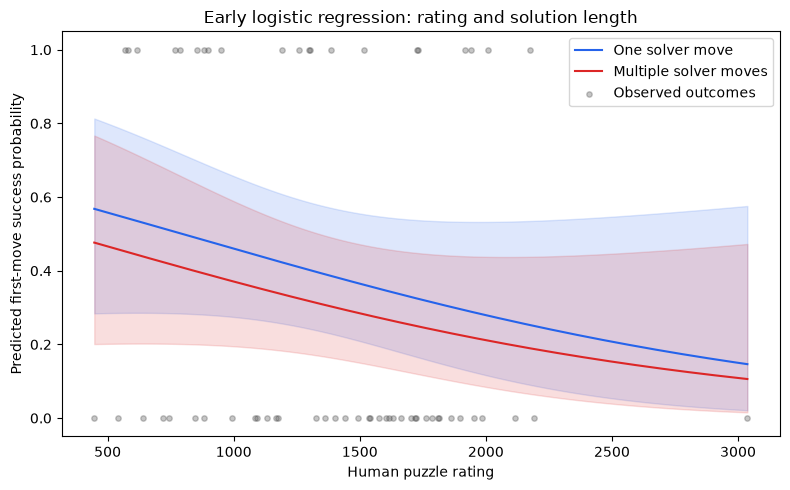

,term,coefficient,odds_ratio,or_ci_low,or_ci_high
0,const,-0.554172,0.574548,0.264328,1.248845
1,rating_500,-0.393284,0.674837,0.387709,1.174606
2,multi_move,-0.368422,0.691825,0.232604,2.057666


In [2]:

fitted=False
if eligible:
    X=sm.add_constant(data[['rating_500','multi_move']],has_constant='add')
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error',PerfectSeparationWarning)
            fit=sm.GLM(y,X,family=sm.families.Binomial()).fit()
        assert fit.converged and np.isfinite(fit.params).all() and np.isfinite(fit.bse).all()
        ci=fit.conf_int()
        coefficients=pd.DataFrame({'term':fit.params.index,'coefficient':fit.params.values,
                                   'odds_ratio':np.exp(fit.params.values),'or_ci_low':np.exp(ci[0].values),'or_ci_high':np.exp(ci[1].values)})
        coefficients.to_csv(OUT/'logistic_coefficients.csv',index=False)
        joblib.dump(fit,OUT/'logistic_regression.joblib')
        fig,ax=plt.subplots(figsize=(8,5))
        rating=np.linspace(data.puzzle_rating.min(),data.puzzle_rating.max(),200)
        for group,color,label in [(0,'#2563eb','One solver move'),(1,'#dc2626','Multiple solver moves')]:
            grid=pd.DataFrame({'const':np.ones(len(rating)),'rating_500':(rating-1500)/500,'multi_move':np.full(len(rating),group)})
            prediction=fit.get_prediction(grid).summary_frame()
            ax.plot(rating,prediction['mean'],color=color,label=label)
            ax.fill_between(rating,prediction['mean_ci_lower'],prediction['mean_ci_upper'],color=color,alpha=.15)
        ax.scatter(data.puzzle_rating,y,s=15,alpha=.3,color='#444444',label='Observed outcomes')
        ax.set(xlabel='Human puzzle rating',ylabel='Predicted first-move success probability',ylim=(-.05,1.05),title='Early logistic regression: rating and solution length')
        ax.legend(loc='best');fig.tight_layout();fig.savefig(FIG/'logistic_regression.png',dpi=180);plt.show()
        fitted=True;display(coefficients)
    except (PerfectSeparationWarning,AssertionError,np.linalg.LinAlgError,ValueError) as error:
        save('analysis_status.json',{'status':'not_fitted','reason':'Logistic model failed convergence/separation checks','error_type':type(error).__name__})
        print('Logistic regression deferred:',type(error).__name__)


## Draw the exploratory decision tree

Numeric CART checks passed.


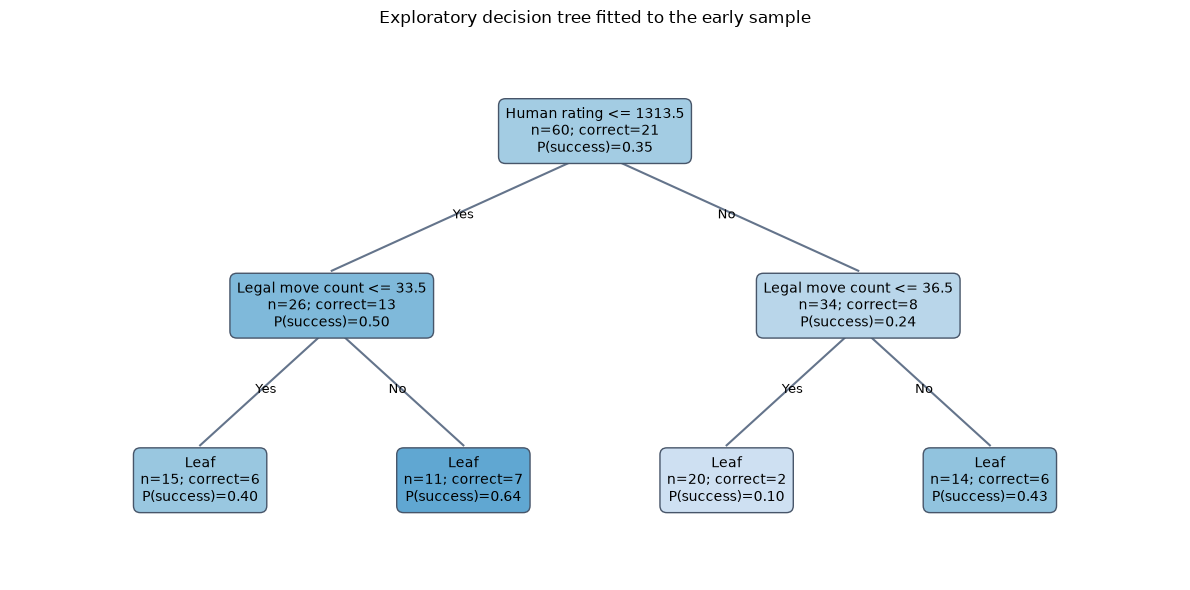

Saved logistic curve, coefficients, numeric CART tree and model artifacts. These are early descriptive results, not final validated models.


In [3]:

# Small, deterministic numeric CART tree: greedy Gini splits, maximum depth 2,
# minimum leaf 10. NumPy/Matplotlib avoid a Windows-blocked scikit-learn DLL.
# Save a portable JSON tree instead of a package-specific pickle.
def fit_tree(frame,target,max_depth=2,min_leaf=10):
    values=frame.to_numpy(dtype=float);labels=np.asarray(target,dtype=int)
    assert len(values)==len(labels) and len(labels)>0 and np.isin(labels,[0,1]).all()
    assert np.isfinite(values).all()
    names=list(frame.columns)
    def grow(indices,depth):
        n=len(indices);positive=int(labels[indices].sum());p=positive/n
        node={'n':n,'correct':positive,'probability':p,'gini':2*p*(1-p),'predicted_class':int(p>.5)}
        if depth>=max_depth or n<2*min_leaf or positive in [0,n]:return node
        best_gain=0.;best=None
        for j,name in enumerate(names):
            unique=np.unique(values[indices,j])
            for threshold in (unique[:-1]+unique[1:])/2:
                left=indices[values[indices,j]<=threshold];right=indices[values[indices,j]>threshold]
                if min(len(left),len(right))<min_leaf:continue
                lp=float(labels[left].mean());rp=float(labels[right].mean())
                gain=node['gini']-(len(left)*2*lp*(1-lp)+len(right)*2*rp*(1-rp))/n
                if gain>best_gain+1e-12:best_gain=gain;best=(name,float(threshold),left,right)
        if best is not None:
            name,threshold,left,right=best
            node.update(feature=name,threshold=threshold,gini_gain=best_gain,left=grow(left,depth+1),right=grow(right,depth+1))
        return node
    return grow(np.arange(len(labels)),0)
def predict_tree(tree,frame):
    predictions=[]
    for _,row in frame.iterrows():
        node=tree
        while 'feature' in node:node=node['left'] if row[node['feature']]<=node['threshold'] else node['right']
        predictions.append(node['predicted_class'])
    return np.asarray(predictions)
# Analytic checks: a perfect numeric split, constant outcomes and an unsplittable feature.
toy=pd.DataFrame({'rating':np.arange(20)})
toy_y=np.r_[np.zeros(10,dtype=int),np.ones(10,dtype=int)]
toy_tree=fit_tree(toy,toy_y,min_leaf=5)
assert toy_tree['threshold']==9.5 and np.array_equal(predict_tree(toy_tree,toy),toy_y)
assert 'feature' not in fit_tree(toy,np.ones(20,dtype=int),min_leaf=5)
assert 'feature' not in fit_tree(pd.DataFrame({'rating':np.ones(20)}),toy_y,min_leaf=5)
print('Numeric CART checks passed.')
if eligible and fitted:
    features=['puzzle_rating','total_solver_moves','legal_moves']
    tree=fit_tree(data[features],y,max_depth=2,min_leaf=10)
    save('decision_tree.json',{'algorithm':'Numeric CART, Gini, depth=2, min_leaf=10, fixed feature/threshold order for ties','features':features,'tree':tree})
    labels={'puzzle_rating':'Human rating','total_solver_moves':'Solver move count','legal_moves':'Legal move count'}
    fig,ax=plt.subplots(figsize=(12,6));ax.set_axis_off()
    def draw(node,x,width,depth,parent=None,branch=None):
        yy=1-depth*.35
        if parent is not None:
            ax.plot([parent[0],x],[parent[1]-.04,yy+.07],color='#64748b',zorder=0)
            ax.text((parent[0]+x)/2,(parent[1]+yy)/2,branch,ha='center',fontsize=9)
        title=f"{labels[node['feature']]} <= {node['threshold']:.1f}" if 'feature' in node else 'Leaf'
        text=title+f"\nn={node['n']}; correct={node['correct']}\nP(success)={node['probability']:.2f}"
        ax.text(x,yy,text,ha='center',va='center',fontsize=10,bbox={'boxstyle':'round,pad=.5','facecolor':plt.cm.Blues(.15+.6*node['probability']),'edgecolor':'#475569'})
        if 'feature' in node:
            draw(node['left'],x-width/2,width/2,depth+1,(x,yy),'Yes')
            draw(node['right'],x+width/2,width/2,depth+1,(x,yy),'No')
    draw(tree,.5,.45,0);ax.set(xlim=(0,1),ylim=(.1,1.2),title='Exploratory decision tree fitted to the early sample')
    fig.tight_layout();fig.savefig(FIG/'decision_tree.png',dpi=180);plt.show()
    save('analysis_status.json',{'status':'early_models_fitted','n':len(data),'model_features':{'logistic':['rating_500','multi_move'],'tree':features},'limitation':'Descriptive in-sample models, not validated predictive accuracy. Balanced sampling, small sample and legal-choice assistance limit generalization.'})
    print('Saved logistic curve, coefficients, numeric CART tree and model artifacts. These are early descriptive results, not final validated models.')
elif eligible:print('Tree also deferred because the primary logistic analysis was not estimable.')


## What these early results show

All **60 fresh puzzles** received provider responses: **21 correct (35%)**, 38 incorrect legal moves and one unparseable final answer. The collection audit independently rescored all 60 raw responses. Development cases and older LLM runs were excluded.

The fitted rating effect is negative: odds ratio **0.675 per 500 rating points**, with a **95% interval of 0.388 to 1.175**, holding the one/multiple-move indicator fixed. Because this interval includes 1, the early sample does **not** establish a clear association between human rating and this deployment's success. A negative fitted curve is not proof of that relationship. The solution-length effect is also uncertain.

The depth-2 tree first splits at rating 1313.5 and then uses legal-move count. Its node rates describe these training examples; they are not validated future accuracy. Both figures are early exploratory results for assisted first-move correctness, not full puzzle solving or a population accuracy estimate.

**Current milestone:** early logistic regression and tree artifacts are available. Next, review the operational outcome and predictor choices, plan a larger sample and validation strategy, and freeze the next study version before additional collection. Do not select a new protocol merely to make a coefficient significant.

The short project README contains the chronological layout. Your three PDFs are unchanged; generated Markdown writing reports were removed. Historical experiment notebooks and strict-output reliability results are preserved in verified archives/numbered historical folders.
